# Домашнее задание №4. Многоклассовая классификация. PCA

**На проверку необходимо приложить следующие файлы:**
  - заполненный ноутбук в формате `.ipynb`.

-------------------------

## Основная часть. (10 баллов)

В этом задании рассматриваются математические свойства метода главных компонент, его реализация и применение к многоклассовой классификации. В ходе решения вам предстоит:
1. Исследовать свойства метрик классификации и вывести постановку задачи PCA.
2. Реализовать PCA и Kernel PCA и сравнить их с библиотечными реализациями.
3. Исследовать влияние числа компонент и выбора ядра на качество многоклассовой классификации.


### Теоретическая часть.

#### Задание 1 (0.5 балла)

1. Покажите, что:
$$
0 \leqslant \text{F1-score} \leqslant 1
$$
2. Покажите, что в случае многоклассовой классификации $Precision_{micro} = Recall_{micro} = Accuracy$

---

##### Ваше решение:

---

#### Задание 2 (0.75 балла)

Пусть $y \in \{1, \ldots, K\}$ и известны вероятности $p_k(x) = P(y=k \mid x)$. $C_{ij}$ — стоимость предсказания класса $j$, если истинный класс равен $i$.

1. Выведите стратегию выбора класса, минимизирующую условный матож стоимости ошибки при данном $x$.
2. Покажите, что для $C_{ii}=0$ и $C_{ij}=1$ при $i \ne j$ стратегия совпадает с предсказанием наиболее вероятного класса.
3. Для трёх классов заданы
$$
p(x)=(0.45,0.35,0.20), \qquad
C=\begin{pmatrix} 0 & 1 & 1 \\ 1 & 0 & 1 \\ 8 & 8 & 0 \end{pmatrix}.$$
Определите наиболее вероятный класс. Вычислите ожидаемую стоимость ошибки при выборе каждого из трёх классов и найдите оптимальный класс для стратегии из пункта 1.


##### Ваше решение:

---


#### Задание 3 (1.5 балла)
В этом задании мы рассмотрим работу PCA как задачу условной оптимизации на единичной сфере. Полученные результаты пригодятся для практической имплементации.  


##### Задача 3.1 (0.5 балла)

[PCA](https://en.wikipedia.org/wiki/Principal_component_analysis) определяется как преобразование данных, в котором проекции упорядочены по убыванию дисперсии
$$
X \in \mathbb R^{n\times p}, \qquad
W = [w_{(1)}, \ldots ,w_{(l)}] \in \mathbb R^{p\times l}, \qquad
T = XW \in \mathbb R^{n \times l}. \tag{1}
$$

Строки $T$ — координаты объектов в пространстве главных компонент, столбцы $W$ — направления проекции. Матрица $X$ содержит $n$ объектов с $p$ признаками.

Как правило, перед применением PCA из каждого признака вычитают его среднее по всем объектам. Далее считаем, что данные уже обработаны таким образом.

Первое направление PCA $w_{(1)}$ выбирают так, чтобы дисперсия проекций объектов на него была максимальной. Эти проекции образуют первый столбец матрицы $T$. Поскольку их среднее равно нулю, максимизация дисперсии эквивалентна максимизации суммы квадратов проекций:
$$
w_{(1)} = \arg\max_{w} \left\{\sum_{i=1}^n T_{i1}^2\right\} = \arg\max_{w} \left\{\|Xw\|^2\right\}. \tag{2}
$$
Чтобы задача (2) имела конечное решение, оптимизацию проводят на единичной сфере:
$$
w_{(1)} = \arg\max_{\|w\| = 1} \left\{\|Xw\|^2\right\}. \tag{3}
$$

Покажите, что решением задачи (3) является вектор $u_{(1)}$, соответствующий максимальному собственному значению $\lambda_{(1)}$ матрицы $X^\top X$.

**Указание:** Воспользуйтесь условиями [ККТ](https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions) для решения задачи условной оптимизации.

$$
\begin{aligned}
\min_{w} \quad & - w^\top X^\top Xw \\
\text{s.t.} \quad & w^\top w - 1 = 0.
\end{aligned}
$$

---

##### Ваше решение:

---

##### Задача 3.2 (0.25 балла)

Вторая компонента $t_{(2)} = Xw_{(2)}$ должна иметь следующую по величине дисперсию.

Однако в таком предположении мы всегда можем выбрать $t_{(2)} = (1 - \varepsilon_{(1)})t_{(1)}$ для сколь угодно малого $\varepsilon_{(1)} > 0$. Аналогично $t_{(3)} = (1 - \varepsilon_{(2)})t_{(2)}$ и так далее. Таким образом, разложение $X$ теряет смысл, поскольку вектора $t_{(1)}, \ldots, t_{(n)}$ являются коллинеарными.

Чтобы получить осмысленное разложение, потребуем чтобы $t_{(2)}$ *некоррелировал* с $t_{(1)}$.

Покажите, что для этого необходимо, чтобы $w_{(2)}^\top u_{(1)} = 0$.

---

##### Ваше решение:

---

##### Задача 3.3 (0.25 балла)

Задача оптимизации для $w_{(2)}$ с учётом 3.2
$$
w_{(2)} = \arg\max_{\|w\| = 1, \\ w \in H_1} \left\{\|Xw\|^2\right\}, \quad H_1 = \{w : w^\top u_{(1)} = 0\}.
$$
В общем случае для $w_{(j)}$
$$
w_{(j)} = \arg\max_{\|w\| = 1, \\ w \in H_{j-1}} \left\{\|Xw\|^2\right\}, \quad H_{j-1} = \left\{w : w^\top u_{(k)} = 0, \,\, k=\overline{1, j-1}\right\}. \tag{4}
$$

Покажите, что решением задачи (4) является вектор $u_{(j)}$, соответствующий $j$-му собственному значению $\lambda_{(j)}$ матрицы $X^\top X$.

**Указание:** Воспользуйтесь условиями [ККТ](https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions) для решения задачи условной оптимизации.

---


##### Ваше решение:

---

##### Задача 3.4 (0.5 балла)

Из предыдущих 3-х пунктов мы выяснили, что процедура построения главных компонент сводится к поиску собственных векторов матрицы $X^\top X$.

На практике бывает полезно центрировать матрицу $X \rightarrow \bar{X}$. Действительно, с точки зрения разложения, выражения $X^\top X$ и $\bar{X}^\top \bar{X}$ связаны соотношением:
$$
X^\top X = \bar{X}^\top \bar{X} + n\mu\mu^\top,
$$
где $\mu = \frac{1}{n}\sum_i x_i$ - выборочное среднее $X$. Тогда, если данные сильно смещены, с.в. и с.з. $X^\top X$ определяются слагаемым смещения и не содержат реальной информации о главных компонентах разложения.

---

В центрированном случае $X = \bar{X}$. Матрица $\bar{X}^\top \bar{X}$ пропорциональна выборочной матрице ковариации $cov(X, X) = \frac{1}{n - 1} \bar{X}^\top \bar{X}$.

---

В Kernel PCA метод главных компонент применяется к преобразованным объектам $\psi(x)$. Их тоже нужно центрировать, но сами векторы мы не вычисляем. Покажем, как выразить центрирование через значения ядра.

Ядро задаётся функцией:
$$
\mathcal{K}: \mathcal{X} \times \mathcal{X} \rightarrow \mathbb{R}, \quad \mathcal{K}(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle.
$$
Здесь $\psi(x)$ — отображение объекта в пространство признаков.

Определим матрицу Грама $K \in \mathbb R^{n \times n}$ через её элементы:
$$
K_{ij} = \mathcal K(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle.
$$

Аналогично PCA, центрируем преобразованные объекты:
$$
\mu_\psi = \frac{1}{n} \sum_{k=1}^n \psi(x_k), \qquad
\bar\psi(x_i) = \psi(x_i) - \mu_\psi.
$$
Матрица Грама центрированных объектов имеет элементы
$$
\bar K_{ij} = \langle \psi(x_i) - \mu_\psi, \psi(x_j) - \mu_\psi \rangle.
$$

Обозначим $J = \frac{1}{n} \mathbf 1 \mathbf 1^\top$, где $\mathbf 1$ — столбец из $n$ единиц. Все элементы матрицы $J$ равны $1/n$.

Покажите, что
$$
\bar K = K - JK - KJ + JKJ.
$$

Эта формула нам пригодится при ручной имплементации Kernel-PCA.

---


##### Ваше решение:

---

#### Задание 4 (0.25 балла)

Вернёмся к постановке из задачи 3.1. Покажите, что PCA инвариантен относительно поворота.

1. Определим матрицу поворота $Q$ и "повёрнутые" данные $\tilde{X}$:
$$
\tilde{X} = XQ.
$$
2. Определим PCA-преобразование над $\tilde{X}$
$$
\widetilde{T} = \tilde{X}\tilde{W}.
$$
3. Тогда инвариантность означает $T = \widetilde{T}$


**Подсказка:** Воспользуйтесь тем, что $W$ и $\tilde{W}$ определяются собственными векторами соответствующих матриц ковариации $X^\top X$ и $\tilde{X}^\top\tilde{X}$, а также что матрица поворота $Q$ обладает свойством ортогональности.

---

##### Ваше решение:

---

### Практическая часть.

In [ ]:
from typing import Callable
import os
import pandas as pd
import numpy as np
import gdown
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
def download_with_shared_id(file_id, filename):
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    gdown.download(url, filename, quiet=False)

### Задание 5 (5 баллов): PCA on synthetic data

В папке с заданием вы найдёте файл `synthetic_data.csv`. Вы можете напрямую загрузить файл во временное окружение или воспользоваться кодом ниже

In [ ]:
synthetic_data_file_id = '1mB6bUInPMxUmvLf58SA33Jd1ZQOe1OWc'
download_with_shared_id(synthetic_data_file_id, 'synthetic_data.csv')
df = pd.read_csv('synthetic_data.csv')
df.head(5)

#### Задача 1 (0.5 балла): Анализ данных

1. Проведите базовый исследовательский анализ предложенных данных.
    *   Исследуйте распределение меток
    *   Визуализируйте зависимости между компонентами примеров

    (Анализ данных не обязан ограничиваться данными пунктами)
2. Выберите метрики для дальнейшего тестирования
3. Для того, чтобы тестирование вашей имплементации PCA было корректным, **важно** не изменять структуру и содержимое `df`.

In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

Разделим данные на обучение и тест, сохранив соотношение классов.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="label").to_numpy()
y = df["label"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Проведите стандартизацию с помощью `StandardScaler`. Обучите преобразование только на `X_train`, затем преобразуйте `X_train` и `X_test`. Сохраните результаты в `X_train` и `X_test`.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

#### Задача 2 (1 балл): Имплементация PCA

Самостоятельно имплементируйте метод главных компонент используя Задание 3.3.

1. Постройте выборочную ковариационную матрицу:
$$
C = \frac{1}{n - 1} \bar X^\top \bar X, \qquad
\bar X = X - \mathbf 1 \mu^\top, \qquad
\mu = \frac{1}{n} \sum_{i=1}^n x_i.
$$
В этой формуле $X$ обозначает `X_train`, $n$ — число обучающих объектов, а $\mu$ — вектор средних значений признаков. Здесь $\mathbf 1$ — столбец из $n$ единиц. Можно использовать `np.cov(X_train, rowvar=False)`.

2. Найдите собственные значения и собственные векторы матрицы $C$.

3. Отсортируйте собственные значения по убыванию и расположите собственные векторы в том же порядке.


In [ ]:
def get_pca_components(cov_matrix):
    raise NotImplementedError("Найдите и отсортируйте собственные значения и векторы")

cov_matrix = np.cov(X_train, rowvar=False)
eigenvalues, eigenvectors = get_pca_components(cov_matrix)

In [ ]:
def assert_eigenvalues(eigenvalues: np.ndarray) -> None:
    expected = np.linalg.eigvalsh(np.cov(X_train, rowvar=False))[::-1]
    assert np.allclose(expected, eigenvalues, rtol=1e-6, atol=1e-8)
    assert np.all(np.diff(eigenvalues) <= 1e-8)
    assert np.allclose(eigenvectors.T @ eigenvectors, np.eye(X_train.shape[1]))
    assert np.allclose(
        cov_matrix @ eigenvectors,
        eigenvectors * eigenvalues,
        rtol=1e-6,
        atol=1e-8,
    )
    print("Success!")

assert_eigenvalues(eigenvalues)

Построим график суммарной объясняемой дисперсии (Cumulative Explained Variance) от количества главных компонент.

In [ ]:
# Calculate explained variance for each component
explained_variance_ratio = eigenvalues / eigenvalues.sum()

# Plot explained variance
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), np.cumsum(explained_variance_ratio), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Number of Principal Components')
plt.grid(True)
plt.show()

Сохраним среднее обучающей выборки в `pca_mean`. Оно пригодится нам далее.

In [ ]:
pca_mean = X_train.mean(axis=0)

#### Задача 3 (1 балл): Классификация

Проведите обучение и тестирование логистической регрессии. Центрированные данные должны проецироваться на полученные главные компоненты (см. (1) в задании 3.1). Постройте графики зависимости выбранных метрик от количества главных компонент. Сделайте выводы.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

#### Задача 4 (2.5 балла): Имплементация Kernel-PCA

Приступим к имплементации Kernel-PCA.

Цель та же - найти с.з. и с.в. Однако вместо поиска их у матрицы ковариации $cov(X, X)$ будем искать их для матрицы Грама (см. задание 3.4).

Будем рассматривать следующие типы ядерных функций:

* Линейное $K_{L}(X,Y) =  X Y^\top$
* Полиномиальное $K_{d, c}(X,Y) = (X Y^\top + c)^d$
* Радиально-базисная функция (РБФ): $[K_\gamma(X, Y)]_{ij} = \exp\{-\gamma \|x_i - y_j\|^2\}$, где $x_i$ и $y_j$ — строки матриц $X$ и $Y$, $\gamma > 0$.
* Сигмоидальная $\sigma_{\gamma}(X, Y) = \tanh{(\gamma\cdot X Y^\top + c)}$
* Косинусное $[K_{\cos}(X, Y)]_{ij} = \frac{x_i^\top y_j}{\|x_i\| \, \|y_j\|}$, где $x_i$ и $y_j$ — строки матриц $X$ и $Y$.

##### Задача 4.1 (0.75 балла)
Необходимо имплементировать перечисленные ядерные функции

In [ ]:
def linear_kernel(X, Y=None):
    if Y is None:
        Y = X
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def poly_kernel(X, Y=None, degree=3, coef=1.):
    if Y is None:
        Y = X
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def rbf_kernel(X, Y=None, gamma=None):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def sigmoid_kernel(X, Y=None, gamma=None, coef=1.):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def cosine_kernel(X, Y=None):
    if Y is None:
        Y = X
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

Полученную матрицу необходимо центрировать. Воспользуемся результатом задания 3.4:
$$
\bar K = K - JK - KJ + JKJ, \qquad
J = \frac{1}{n} \mathbf 1 \mathbf 1^\top.
$$
Здесь $K_{ij} = \mathcal K(x_i, x_j)$, а $\mathbf 1$ — столбец из $n$ единиц.

##### Задача 4.2 (0.25 балла)
Имплементируйте центрирование матрицы Грама

In [ ]:
def center_kernel(K):
    # YOUR CODE HERE:
    ###########################
    ### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
    ###########################
    pass

Ниже дана готовая реализация `KernelPCA`, использующая ваши функции ядра, центрирования и поиска собственных векторов. `fit` сохраняет обучающие объекты и статистики матрицы ядра. `transform` строит ядро между новыми и обучающими объектами и центрирует его с использованием сохранённых статистик. Используйте `fit_transform(X_train)` для обучения и `transform(X_test)` для теста.


In [ ]:
class KernelPCA:
    def __init__(self, n_components: int, kernel: Callable, **kernel_params) -> None:
        self.n_components = n_components
        if not callable(kernel):
            raise TypeError("kernel must be callable")
        self.kernel = kernel
        self.kernel_params = kernel_params

    def fit(self, X):
        self.X_fit_ = np.array(X, dtype=float, copy=True)
        K = self.kernel(self.X_fit_, **self.kernel_params)
        self.K_fit_mean_ = K.mean(axis=0)
        self.K_fit_all_mean_ = K.mean()
        K_centered = center_kernel(K)
        eigenvalues, eigenvectors = get_pca_components(K_centered)
        # Нулевые и отрицательные собственные значения требуют более аккуратной обработки.
        eigenvalues = np.clip(eigenvalues, a_min=0, a_max=None)
        self.eigenvalues = eigenvalues[:self.n_components]
        self.eigenvectors = eigenvectors[:, :self.n_components] / np.sqrt(
            self.eigenvalues + 1e-10
        )
        return self

    def transform(self, X):
        K = self.kernel(np.asarray(X), self.X_fit_, **self.kernel_params)
        K_centered = (
            K - K.mean(axis=1, keepdims=True)
            - self.K_fit_mean_[None, :] + self.K_fit_all_mean_
        )
        return K_centered @ self.eigenvectors

    def fit_transform(self, X):
        return self.fit(X).transform(X)

Проверка имплементации

In [ ]:
def assert_kpca():
    from sklearn.metrics.pairwise import pairwise_kernels

    X_fit = X_train[:30]
    X_new = X_test[:11]
    n_components = 5
    configurations = [
        (linear_kernel, "linear", {}),
        (poly_kernel, "poly", {"gamma": 1.0, "degree": 3, "coef0": 1.0}),
        (rbf_kernel, "rbf", {"gamma": 1.0 / X_fit.shape[1]}),
        (sigmoid_kernel, "sigmoid", {"gamma": 1.0 / X_fit.shape[1], "coef0": 1.0}),
        (cosine_kernel, "cosine", {}),
    ]
    for kernel, name, params in configurations:
        K = pairwise_kernels(X_fit, metric=name, **params)
        K_new = pairwise_kernels(X_new, X_fit, metric=name, **params)
        assert np.allclose(kernel(X_fit), K)
        assert np.allclose(kernel(X_new, X_fit), K_new)
        H = np.eye(len(X_fit)) - np.ones((len(X_fit), len(X_fit))) / len(X_fit)
        expected_centered = H @ K @ H
        assert np.allclose(center_kernel(K), expected_centered, atol=1e-8)
        eigenvalues, eigenvectors = np.linalg.eigh(expected_centered)
        order = np.argsort(eigenvalues)[::-1][:n_components]
        expected_values = eigenvalues[order]
        assert np.all(expected_values > 0)
        expected_vectors = eigenvectors[:, order] / np.sqrt(expected_values)
        expected_train = expected_centered @ expected_vectors
        expected_new = (
            K_new - K_new.mean(axis=1, keepdims=True)
            - K.mean(axis=0)[None, :] + K.mean()
        ) @ expected_vectors
        model = KernelPCA(n_components, kernel)
        actual_train = model.fit_transform(X_fit)
        actual_new = model.transform(X_new)
        assert np.allclose(model.eigenvalues, expected_values, rtol=1e-6, atol=1e-8)
        assert np.allclose(actual_train, model.transform(X_fit))
        assert np.allclose(
            actual_train @ actual_train.T,
            expected_train @ expected_train.T,
            rtol=1e-5, atol=1e-7,
        )
        assert np.allclose(
            actual_new @ actual_train.T,
            expected_new @ expected_train.T,
            rtol=1e-5, atol=1e-7,
        )
        assert np.allclose(actual_new, model.transform(np.vstack([X_new, X_new]))[:len(X_new)])
    print("Success!")

assert_kpca()

##### Задача 4.3 (1 балл)
Проведите обучение и тестирование логистической регрессии. Данные должны проецироваться на главные компоненты `KernelPCA` для различных типов ядерных функций.

Композитное ядро можно получить сложением или поэлементным перемножением двух положительно полуопределённых ядер. Например, $[K(X, Y)]_{ij} = [K_\gamma(X, Y)]_{ij} \cdot [K_{d, c}(X, Y)]_{ij}$. Добавьте хотя бы одно такое ядро и сравните его с исходными.

Сравните зависимость качества классификации от количества главных компонент для разных ядер. Сравните результаты с линейным ядром. Сделайте выводы.

**Важно!** Используйте команду `%%time` для подсчета выполнения полной процедуры обучения. Это потребуется для сравнения с имплементацией `sklearn` в следующем пункте.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

##### Задача 4.4 (0.5 балла)
Проведите аналогичное обучение для библиотечной имплементации `from sklearn.decomposition import KernelPCA as SKKernelPCA`. Используйте то же разбиение на обучение и тест. Примените `fit_transform` на обучающей выборке и `transform` на тестовой.

Используйте одинаковые параметры ядер в обеих реализациях. Для библиотечного полиномиального ядра задайте `gamma=1`, `degree=3`, `coef0=1`.

Сравните время и качество классификации. Есть ли различие? Сделайте выводы.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

### Задание 6 (2 балла): PCA Image Compression

Метод главных компонент используют для понижения размерности данных. Давайте воспользуемся этим для компрессии изображения. Чтобы понять интуицию сжатия, обратимся к матричному разложению PCA

$$
\underbrace{X}_{n \times p} \approx \underbrace{T_l}_{n \times l} \underbrace{W_l^\top}_{l \times p} + \underbrace{\mathbf 1 \mu^\top}_{n \times p}.
$$
Здесь $X$ — матрица одного канала изображения, $n$ — число строк, $p$ — число столбцов, $\mu$ — вектор средних по столбцам, а $l < p$ — число оставленных главных компонент.

В папке с заданием вы найдёте 3-х канальное изображение `sean-yalda.jpg`. Вам необходимо получить сжатое информативное представление этого изображения.

Воспользуемся автоматическим скачиванием через shared-ссылку (вы можете напрямую добавить картинку в окружение ноутбука)

(3375, 6000, 3)


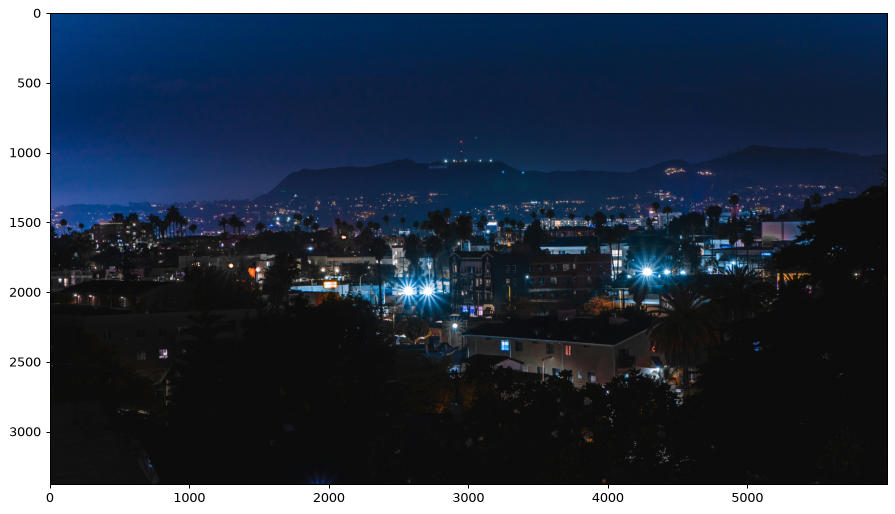

In [ ]:
image_file_id = "1geYxsmnvVJKQkyl-WB0izTqi-fLz8UET"
download_with_shared_id(image_file_id, 'sean-yalda.jpg')

# Load image
image = Image.open("sean-yalda.jpg")
image_array = np.array(image).astype(np.uint8)
print(image_array.shape)

plt.figure(figsize=[12,8])
plt.imshow(image)

Обратите внимание, что мы работаем с форматом `uint8`.

Сделаем пробное сжатие с помощью PCA.

Метод главных компонент работает с двумерными матрицами, поэтому 3-х канальное изображение необходимо преобразовать. Для примера преобразуем изображение в серое, усреднив значения по трём каналам.

transformed data shape: (3375, 100)


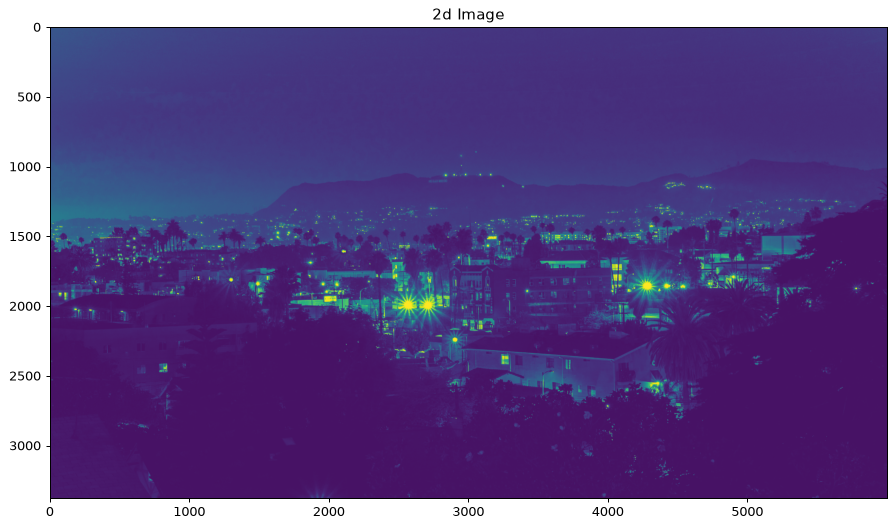

In [ ]:
from sklearn.decomposition import PCA

image_2d = image_array.mean(axis=2).astype(np.uint8)
plt.figure(figsize=[12,8])
plt.imshow(image_2d, cmap="viridis")
plt.title("2d Image")

pca = PCA(n_components=100)
transformed_data = pca.fit_transform(image_2d)
print(f"transformed data shape: {transformed_data.shape}")

Мы получили сжатое представление $T_l$. Для реконструкции $X$, необходимо обратно перевести $T_l \rightarrow \tilde{X}$

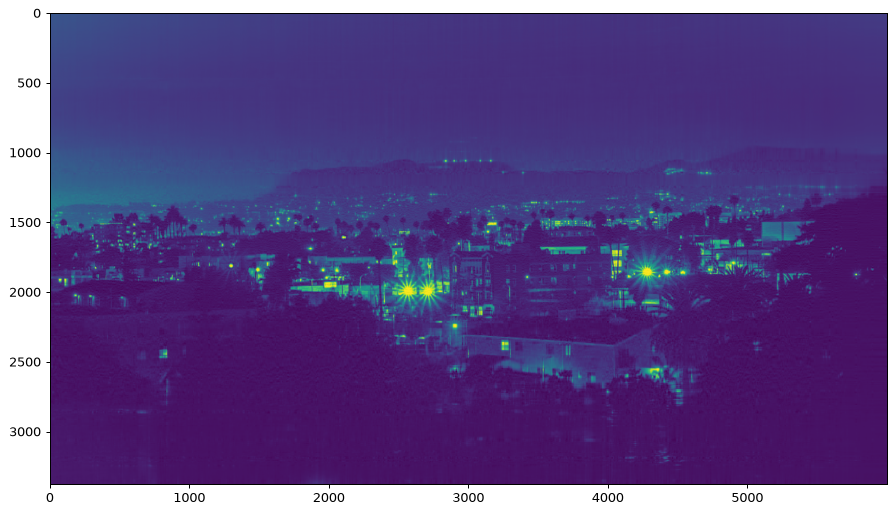

In [ ]:
reconstructed_image = np.dot(transformed_data, pca.components_) + pca.mean_
# Ограничим значения пикселей диапазоном [0, 255] перед преобразованием в uint8.
reconstructed_image = np.clip(reconstructed_image, 0, 255).astype(np.uint8)
plt.figure(figsize=[12,8])
plt.imshow(reconstructed_image, cmap="viridis")

Степень сжатия будем определять как отношение размера оригинальной картинки к размеру всех ингредиентов для реконструкции:

In [ ]:
# Comparative analysis
original_size = image_array.nbytes / 1e+6
compressed_size = transformed_data.nbytes / 1e+6 + pca.components_.nbytes / 1e+6 + pca.mean_.nbytes / 1e+6

print(f"Original size: {original_size} Megabytes,\nPCA Compressed size: {compressed_size} Megabytes,\nRelative compression: {round(original_size / compressed_size, 3)} times")

Original size: 60.75 Megabytes,
PCA Compressed size: 7.548 Megabytes,
Relative compression: 8.048 times


Качество компрессии будем определять с помощью [`structural_similarity`](https://scikit-image.org/docs/0.24.x/auto_examples/transform/plot_ssim.html):
$$
\text{SSIM}(x, y) = \dfrac{(2\mu_x\mu_y + c_1)(2\Sigma_{xy} + c_2)}{(\mu_x^2 + \mu_y^2 + c_1)(\sigma_x^2 + \sigma_y^2 + c_2)} \in [-1, 1],
$$

где $\mu_x$ и $\mu_y$ — средние, $\sigma_x$ и $\sigma_y$ — стандартные отклонения, а $\Sigma_{xy}$ — ковариация значений пикселей в соответствующих локальных окнах изображений $x$ и $y$. Итоговое значение SSIM получают усреднением по окнам. Константы $c_1$ и $c_2$ нужны для численной устойчивости.

Индекс $\text{SSIM}$ интерпретируется как структурная близость изображений. $\text{SSIM} = 1$ означает идеальную близость (изображения одинаковые). Для независимых шумовых изображений SSIM обычно близок к нулю. При выраженной отрицательной корреляции локальных структур SSIM может принимать отрицательные значения.

Обратите внимание, несмотря на преобразование исходного изображения к двумерному виду, финальное качество меряется в сравнении с оригиналом.

В связи с этим, реконструированное изображение необходимо привести к 3-х мерному виду. Для этого давайте просто скопируем его вдоль новой оси.

In [ ]:
from skimage.metrics import structural_similarity as ssim

image_3d = np.stack([image_2d, image_2d, image_2d], axis=-1).astype(np.uint8)
reconstructed_image_3d = np.stack([reconstructed_image, reconstructed_image, reconstructed_image], axis=-1).astype(np.uint8)

ssim_index = ssim(image_array, reconstructed_image_3d, win_size=5, channel_axis=-1, data_range=255)
ssim_index_2 = ssim(image_2d, reconstructed_image, win_size=5, channel_axis=None, data_range=255)
ssim_index_3 = ssim(image_array, image_3d, win_size=5, channel_axis=-1, data_range=255)

print(f"Target SSIM: {ssim_index}")
print(f"SSIM between 2d images: {ssim_index_2}")
print(f"SSIM between Grayscale and Original Image: {ssim_index_3}")

Качество снижается как из-за усреднения каналов, так и из-за ограничения числа главных компонент. Количество главных компонент в этом примере было выбрано произвольно.

#### Задача 1 (1.25 балла): Channel-wise Compression

Вам необходимо провести более аккуратную компрессию, сжимая изображение независимо по каждому из каналов и подбирая для каждого из них своё количество компонент.

**Вам необходимо достигнуть степени сжатия не менее чем в 1.5 раза при SSIM > 0.9.**

In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

#### Задача 2 (0.75 балла): Kernel-PCA Image Compression

Повторите эксперимент для PCA с нелинейными ядрами (rbf, poly).

Используйте библиотечный KernelPCA с параметром <code>fit_inverse_transform=True</code>. Для приближённого восстановления изображения примените метод <code>inverse_transform</code>.

1. Какого индекса structural similarity в таком случае вам удалось добиться?
2. Какая в таком случае получается степень сжатия? (Вопрос с подвохом)

При подсчёте степени сжатия учитывайте все данные, необходимые для восстановления изображения.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################

---

## Дополнительная часть. (10 баллов)


### Задание 7 (4 балла): Robust PCA

Robust PCA позволяет представить наблюдаемую матрицу $M$ в виде суммы:
$$
M = L + S,
$$
где $L$ — малоранговая матрица, а $S$ — разреженная матрица, содержащая большое количество нулей. Такое разложение позволяет отделить основную структуру данных от редких искажений, которые могут иметь большую величину.

Вместе с этим, существует много приложений, где природа данных естественным образом моделируется низкоранговым и разреженным вкладами.
* *Видеонаблюдение*: Статичный фон выступает низкоранговым слагаемым, в то время как движущиеся объекты - разреженным.
* *Распознавание по лицу*: статичным объектом является лицо человека (низкоранговое приближение), в то время как различные искажения и фон моделируются разреженной матрицей.
* [Тематическое моделирование](http://www.machinelearning.ru/wiki/index.php?title=%D0%92%D0%B5%D1%80%D0%BE%D1%8F%D1%82%D0%BD%D0%BE%D1%81%D1%82%D0%BD%D1%8B%D0%B5_%D1%82%D0%B5%D0%BC%D0%B0%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B5_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8_%28%D0%BA%D1%83%D1%80%D1%81_%D0%BB%D0%B5%D0%BA%D1%86%D0%B8%D0%B9%2C_%D0%9A.%D0%92.%D0%92%D0%BE%D1%80%D0%BE%D0%BD%D1%86%D0%BE%D0%B2%29): тематическая модель является задачей стохастического матричного разложения.


Выпишем задачу оптимизации:

$$
\begin{aligned}
\min_{L, S} \quad & \operatorname{rank}(L) + \alpha \cdot \operatorname{nnz}(S) \\
\text{s.t.} \quad & M = L + S.
\end{aligned}
$$

Здесь $\alpha > 0$ — коэффициент, задающий вклад разреженной компоненты, а $\operatorname{nnz}(S)$ — количество ненулевых элементов матрицы $S$. Эта задача невыпуклая и сложна для решения. Поэтому её [заменяют выпуклой задачей](https://arxiv.org/pdf/0912.3599):

$$
\begin{aligned}
\min_{L, S} \quad & \|L\|_{\ast} + \alpha \cdot \|S\|_1 \\
\text{s.t.} \quad & M = L + S.
\end{aligned}
$$

Здесь $\|L\|_{\ast} = \sum_i \sigma_i(L)$ — ядерная норма матрицы, $\sigma_i(L)$ — её сингулярные числа, а $\|S\|_1 = \sum_{i, j} |S_{ij}|$ — сумма модулей всех элементов матрицы.


В папке с заданием вы найдёте имплементацию Robust PCA в файле `r_pca.py`. Можете напрямую добавить его в текущее окружение или воспользоваться кодом ниже.

**Примечание:** [Оригинальная имплементация](https://github.com/dganguli/robust-pca) была адаптирована под версию `NumPy 2.0`.

In [ ]:
rpca_file_id = '1MSzmYJa-nfTOlUNA9J5rBCX8F_AeCNFX'
download_with_shared_id(rpca_file_id, 'r_pca.py')

In [ ]:
import r_pca

В качестве примера применения robust PCA мы разложим видеоряд на фон и движущиеся объекты. В папке с заданием вы найдёте видео `video_1.mp4`.



Установим библиотеку `moviepy` для работы с видео

In [ ]:
%pip install -q moviepy==1.0.3

In [ ]:
import moviepy.editor as mpe

Воспользуемся автоматическим скачиванием через shared-ссылку (вы можете напрямую добавить видеоряд в окружение ноутбука)

In [ ]:
video_file_id = "1UVn7QuPjLc6Gq8iFBOfYcegGdsVsquUy"
download_with_shared_id(video_file_id, 'video_1.mp4')

video = mpe.VideoFileClip('video_1.mp4')
print(f"Frame per second video: {video.fps}")
video.ipython_display(width=300, maxduration=250)

Видно, что видео черно-белое, т.е. содержит 1 канал изображения. Представим его в виде трехмерного массива размеров `(#кадров) x (#пикселей по горизонтали) x (#пикселей по вертикали)`.

In [ ]:
def video_to_array(video):
    duration = int(video.duration)
    nframes = int(video.fps * video.duration)
    size_h, size_w = video.size
    arr = np.zeros([nframes, size_w, size_h])
    for i in range(nframes):
        arr[i, :, :] = video.get_frame(i/nframes * duration)[:, :, 0].astype(float)
    print('image size: {1:} x {2:}, \nnumber of frames: {0:}'.format(nframes, size_w, size_h))
    return arr

arr = video_to_array(video)
plt.imshow(arr[0, :, :], cmap='gray')
plt.title('The first frame of the video')

#### Задача 1 (1 балл): Подготовка матрицы кадров

С помощью функции `np.reshape(...)` получите из трехмерного массива `arr` двумерный массив `M` размера `(size_h * size_w) x nframes`, каждым столбцом которого является изображение размера `size_h x size_w`, представленное в виде вектора с `size_h * size_w` элементами.

In [ ]:
nframes, size_w, size_h = arr.shape

# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################
# output: matrix M

Если всё сделано правильно, то вы сможете восстановить первый кадр из первого столбца:

In [ ]:
first_frame = # TO BE FILLED
plt.imshow(first_frame, cmap='gray')
plt.title('The first frame of the video')

#### Задача 2 (2 балла): Разложение и восстановление видео

Вычисление разложения для всех кадров может занять много времени. Поэтому возьмите первую четверть кадров и оставьте в ней каждый второй кадр. Обозначим полученную матрицу $M_t$. Создайте объект класса `R_pca` с параметром $\mu = 0.68$ и запустите метод `fit`, чтобы получить разложение $M_t \approx L + S$.

Параметр $\mu$ управляет работой алгоритма оптимизации. Он отличается от коэффициента $\alpha$ в целевой функции. В реализации `r_pca.py` коэффициенту $\alpha$ соответствует параметр `lmbda`.

Визуализируйте результат разложения и восстановите видео движущихся объектов, заполнив ячейки ниже.


In [ ]:
# YOUR CODE HERE:
###########################
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
###########################
# 1. Mt == Take 1/4 part of M and only each 2nd frame
# 2. solver = r_pca.R_pca(Mt, mu=0.68)
# 3. L, S = solver.fit(max_iter=4000, iter_print=100)

Отрисуйте один и тот же кадр исходного видео $M_t$, фона $L$ и движущихся объектов $S$.


In [ ]:
_, axs = plt.subplots(1,3, figsize=(15,10))
axs[0].imshow(..., cmap='gray') # TO BE FILLED
axs[0].set_title("Исходное изображение")
axs[1].imshow(..., cmap='gray') # TO BE FILLED
axs[1].set_title("Фон")
axs[2].imshow(..., cmap='gray') # TO BE FILLED
axs[2].set_title("Движущиеся объекты");

Заполните пропуски в функции `M_to_video`, преобразующей матрицу обратно в видео.

In [ ]:
def M_to_video(M, fps, size_w, size_h, normalize=False):
    nframes = M.shape[1]
    arr = # YOUR CODE HERE:
    print(arr.shape)
    if normalize:
        arr = np.abs(arr)
        scale = np.quantile(arr, 0.995)
        if scale == 0:
            scale = arr.max()
        if scale > 0:
            arr = np.clip(arr / scale * 255, 0, 255)
    def make_frame(t):
        index = int(t * fps)
        frame = arr[index, :, :]
        frame = np.clip(frame, 0, 255)
        frame_rgb = frame[:, :, np.newaxis][:, :, [0,0,0]]
        return frame_rgb
    return mpe.VideoClip(make_frame, duration=nframes / fps)

Посмотрим на видео движущихся объектов. Компонента $S$ содержит как положительные, так и отрицательные отклонения от фона, причём их величина часто мала. Для отображения возьмём модуль и усилим контраст с помощью `normalize=True`. Масштаб зададим по 99.5-му процентилю модулей значений всего видео, чтобы он был одинаковым для всех кадров. Это преобразование используется только для визуализации.


In [ ]:
video_rpca = M_to_video(..., video.fps / 2, size_w, size_h, normalize=True) # TO BE FILLED
video_rpca.ipython_display(width=300, maxduration=250, fps=video.fps / 2)

#### Задача 3 (1 балл)

Объясните, почему фон видео можно описать малоранговой матрицей, а движущиеся объекты — разреженной. Оцените качество полученного разделения и укажите ситуации, в которых эти предположения могут нарушаться.


##### Ваше решение:

---


### Задание 8 (6 баллов): PTB-XL dimensionality reduction

Вспомним про набор данных [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/) с одного из прошлых семинаров. Там, имея репрезентативные представления модели, полученной в результате инференса электрокардиограмм, мы обучали логистическую регрессию на задаче multilabel-классификации.



**Описание набора данных**

Вспомним структуру датасета

1. Скачаем представления и метаданные об ЭКГ

In [ ]:
ptbxl_id = '1BggNYgJEU1AlL3eDnCJZUFX5HBnRb9Fg'
download_with_shared_id(ptbxl_id, 'ptbxl_features.zip')

In [ ]:
!unzip ptbxl_features.zip

In [6]:
df = pd.read_csv('ptbxl_features/map_file.csv')
df.head(5)

,file_name,ecg_shape,frequency,ecg_duration,mkv,patient_id,doctor_id,device_name,report,scp_codes,...,burst_noise,electrodes_problems,pacemaker,strat_fold,extra_beats,heart_axis,infarction_stadium1,infarction_stadium2,age,target
0,00000_00001_hr.npz,"(12, 5000)",500,10,1,15709,NaN,CS-12 E,sinusrhythmus periphere niederspannung,"['NORM', 'LVOLT', 'SR']",...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,56.0,[0]
1,00000_00002_hr.npz,"(12, 5000)",500,10,1,13243,NaN,CS-12 E,sinusbradykardie sonst normales ekg,"['NORM', 'SBRAD']",...,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,19.0,[0]
2,00000_00003_hr.npz,"(12, 5000)",500,10,1,20372,NaN,CS-12 E,sinusrhythmus normales ekg,"['NORM', 'SR']",...,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,37.0,[0]
3,00000_00004_hr.npz,"(12, 5000)",500,10,1,17014,NaN,CS-12 E,sinusrhythmus normales ekg,"['NORM', 'SR']",...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,24.0,[0]
4,00000_00005_hr.npz,"(12, 5000)",500,10,1,17448,NaN,CS-12 E,sinusrhythmus normales ekg,"['NORM', 'SR']",...,NaN,NaN,NaN,4,NaN,NaN,NaN,NaN,19.0,[0]


2. Метаданные представлены следующими полями

In [ ]:
df.columns

3. Название файла `file_name` указывает на соответствующую ЭКГ, для которой существует репрезентативное представление

In [ ]:
features_dir = 'ptbxl_features'
file_name = df.iloc[0]['file_name']
feature_path = os.path.join(features_dir, file_name)
feature = np.load(feature_path)['arr_0']
feature.shape

Реальный размер ЭКГ, конечно, гораздо больше, поэтому мы пользуемся заготовленными эмбеддингами

In [ ]:
!pip install wfdb
import wfdb

dat_id = '1P90YQqR1oJM3Jy2ILezzfvVHqS2uv3Fe'
hea_id = '1tkZP35O8fV7eX8E2UoPhcXvFaKGM5Imd'
download_with_shared_id(dat_id, '00001_hr.dat')
download_with_shared_id(hea_id, '00001_hr.hea')

record = wfdb.rdrecord('00001_hr')
signal = record.p_signal

In [ ]:
signal.shape

4. Целевым столбцом является [стандартизированная разметка патологий](https://www.cinc.org/archives/2016/pdf/090-500.pdf).



In [12]:
df['scp_codes'].head(5)

,scp_codes
0,"['NORM', 'LVOLT', 'SR']"
1,"['NORM', 'SBRAD']"
2,"['NORM', 'SR']"
3,"['NORM', 'SR']"
4,"['NORM', 'SR']"


Расшифровку соответствующих кодов можно посмотреть в следующем [файле](https://files.stroyinf.ru/Data2/1/4293740/4293740830.pdf).

Давайте выделим следующие патологии (нарушения работы сердца):
1. AFIB - Atrial FIBrillation
2. PVC - Premature Ventricular Contractions
3. CRBBB - Complete Right Bundle Branch Block
4. CLBBB - Complete Left Bundle Branch Block
5. 1AVB - 1st degree AV Block
6. LAFB - Left Anterior Fascicular Block

И следующие "нормальные" состояния сердца:
1. NORM - нормальное положение оси сердца.
2. SR - синусовый ритм.

К каждой из кодировок можно получить доступ следующим способом.

(А уже по имени файла - соответствующее репрезентативное представление)

In [13]:
df[df['scp_codes'].str.contains('LAFB')].head(5)

,file_name,ecg_shape,frequency,ecg_duration,mkv,patient_id,doctor_id,device_name,report,scp_codes,...,burst_noise,electrodes_problems,pacemaker,strat_fold,extra_beats,heart_axis,infarction_stadium1,infarction_stadium2,age,target
66,00000_00103_hr.npz,"(12, 5000)",500,10,1,13722,NaN,CS-12 E,sinustachykardie ueberdrehter linkstyp periphe...,"['IMI', 'LAFB', 'ABQRS', 'STACH']",...,NaN,NaN,NaN,4,NaN,ALAD,Stadium II-III,NaN,39.0,[0]
108,00000_00182_hr.npz,"(12, 5000)",500,10,1,12000,NaN,AT-6 C,sinusrytm extrem vÄnster el-axel ospecifikt sk...,"['ASMI', 'LAFB', '1AVB', 'SR']",...,NaN,NaN,NaN,6,1ES,NaN,Stadium III,NaN,72.0,[0]
129,00000_00220_hr.npz,"(12, 5000)",500,10,1,21580,NaN,CS-12,sinusrhythmus ueberdrehter linkstyp linksanter...,"['LAFB', 'ABQRS', 'SR']",...,NaN,NaN,NaN,5,NaN,ALAD,NaN,NaN,46.0,[0]
134,00000_00226_hr.npz,"(12, 5000)",500,10,1,20431,NaN,CS-12,sinusrhythmus ueberdrehter linkstyp linksanter...,"['LAFB', 'SR']",...,NaN,NaN,NaN,3,NaN,ALAD,NaN,NaN,83.0,[0]
140,00000_00235_hr.npz,"(12, 5000)",500,10,1,15405,NaN,CS-12,sinusbradykardie ...,"['NORM', 'LAFB', 'SBRAD']",...,NaN,NaN,NaN,4,NaN,ALAD,NaN,NaN,79.0,[0]


В отличие от семинара, к этому домашнему заданию мы владеем инструментами понижения размерности. Поскольку задание про PCA, давайте использовать только его.

#### Задача 1 (1 балл): Подготовка данных

Выберите одну задачу для исследования. Например, можно сравнить записи с одной из патологий и записи с метками `NORM` и `SR`, исследовать людей младше 20 и старше 87 лет или поставить задачу multilabel-классификации патологий. Можно предложить свою задачу на основе метаданных.

Сформулируйте задачу, подготовьте представления ЭКГ и целевые метки. Опишите состав выборки и выберите метрики классификации. Для бинарной задачи можно взять по 200 записей каждого класса.

#### Задача 2 (2 балла): Визуализация

Понизьте размерность представлений до двух компонент с помощью PCA и Kernel PCA. Для Kernel PCA рассмотрите несколько ядер. Постройте визуализации с обозначением классов и сравните полученные результаты. Для multilabel-задачи выберите одну из меток для раскраски объектов.

#### Задача 3 (2 балла): Классификация

Обучите логистическую регрессию на исходных представлениях и после понижения размерности с помощью PCA и Kernel PCA. Исследуйте влияние числа компонент на качество классификации.

Используйте одно и то же разбиение на обучение и тест во всех экспериментах. Стандартизацию и преобразования PCA и Kernel PCA обучайте только на обучающей выборке. К тестовой выборке применяйте уже обученные преобразования. Для multilabel-задачи обучите отдельный классификатор для каждой метки.

#### Задача 4 (1 балл): Выводы

Сравните результаты визуализации и классификации. Объясните, как выбор метода, ядра и числа компонент влияет на полученные представления и качество классификации. Укажите ограничения проведённого эксперимента.
